In [10]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import shap
import joblib
import sys

PROJECT_ROOT=Path.cwd().parent
DATASET_DIR=PROJECT_ROOT / 'datasets' / 'House-Prices-Data' / 'train.csv'

df=pd.read_csv(DATASET_DIR)
y=df['SalePrice']

In [11]:
df.sample(10)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
743,744,80,RL,70.0,12886,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,10,2009,WD,Normal,175000
531,532,70,RM,60.0,6155,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,128000
1412,1413,90,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2009,WD,Normal,90000
112,113,60,RL,77.0,9965,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,10,2007,New,Partial,383970
710,711,30,RL,56.0,4130,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2008,WD,Normal,52000
209,210,20,RL,75.0,8250,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2008,WD,Normal,145000
978,979,20,RL,68.0,9450,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Abnorml,110000
1109,1110,20,RL,107.0,11362,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,3,2009,WD,Normal,280000
870,871,20,RL,60.0,6600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2009,WD,Normal,109500
911,912,20,RL,NaN,9286,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,10,2009,WD,Normal,143500


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [13]:
for col in df.columns:
    print(df[col].value_counts())
    print("\n")


Id
1       1
2       1
3       1
4       1
5       1
       ..
1456    1
1457    1
1458    1
1459    1
1460    1
Name: count, Length: 1460, dtype: int64


MSSubClass
20     536
60     299
50     144
120     87
30      69
160     63
70      60
80      58
90      52
190     30
85      20
75      16
45      12
180     10
40       4
Name: count, dtype: int64


MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64


LotFrontage
60.0     143
70.0      70
80.0      69
50.0      57
75.0      53
        ... 
182.0      1
160.0      1
152.0      1
153.0      1
46.0       1
Name: count, Length: 110, dtype: int64


LotArea
7200     25
9600     24
6000     17
10800    14
8400     14
         ..
10652     1
12968     1
11924     1
14260     1
9550      1
Name: count, Length: 1073, dtype: int64


Street
Pave    1454
Grvl       6
Name: count, dtype: int64


Alley
Grvl    50
Pave    41
Name: count, dtype: int64


LotShape
Reg    925
IR1    48

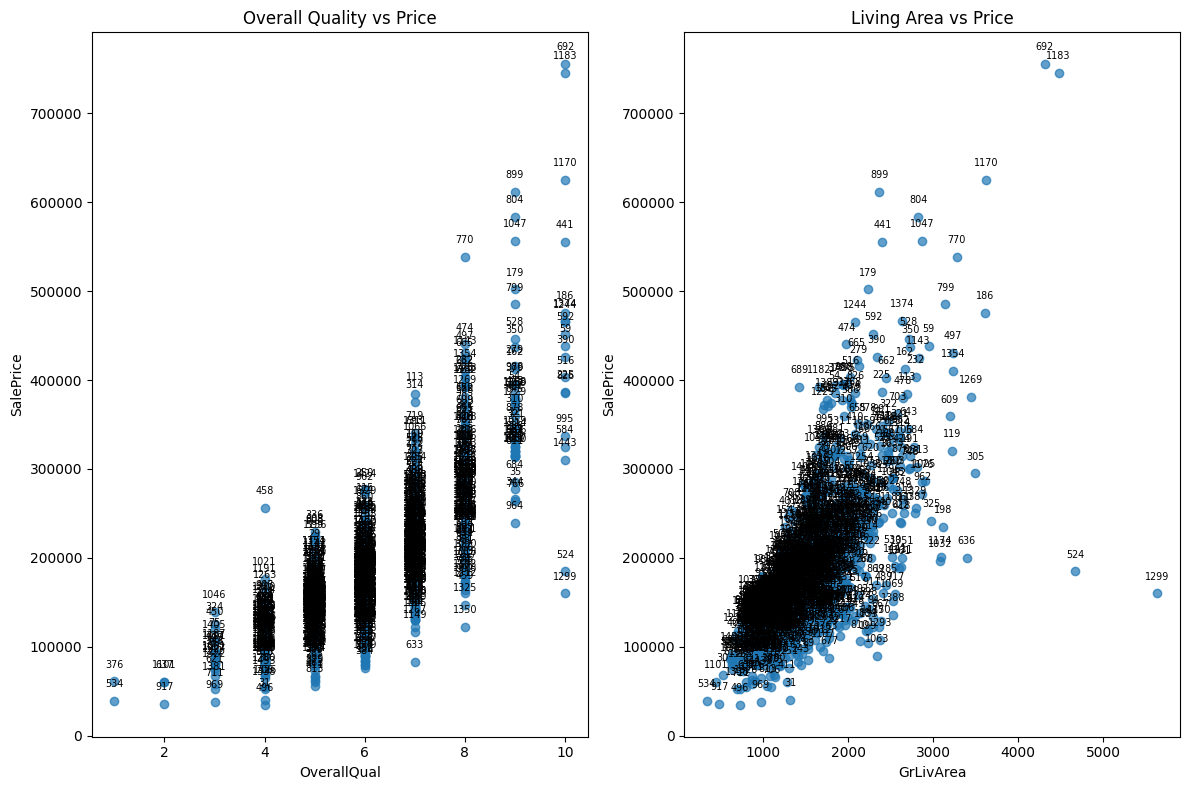

In [14]:
fig, axs=plt.subplots(nrows=1, ncols=2, figsize=(12, 8))

axs[0].scatter(df['OverallQual'], y, alpha=0.7)
for i, label in enumerate(df['Id']):
    axs[0].annotate(label, (df['OverallQual'][i], y[i]), textcoords="offset points", xytext=(0, 10), fontsize='x-small', ha='center')
axs[0].set_title("Overall Quality vs Price")
axs[0].set_xlabel("OverallQual")
axs[0].set_ylabel("SalePrice")

axs[1].scatter((df['GrLivArea']), y, alpha=0.7)
for i, label in enumerate(df['Id']):
    axs[1].annotate(label, (df['GrLivArea'][i], y[i]), textcoords="offset points", xytext=(0, 10), fontsize='x-small', ha='center')
axs[1].set_title("Living Area vs Price")
axs[1].set_xlabel("GrLivArea")
axs[1].set_ylabel("SalePrice")

plt.tight_layout()
plt.show()

* Here we can see house no. **524** and **1299** are extreme outliers, presumably sold under undisclosed conditions.

*(Since deletion is 0-based in dataframe indices 523 and 1298 are meant too be deleted)*

In [15]:
df['Utilities'].value_counts(), df['Street'].value_counts(), df['PoolArea'].value_counts()

(Utilities
 AllPub    1459
 NoSeWa       1
 Name: count, dtype: int64,
 Street
 Pave    1454
 Grvl       6
 Name: count, dtype: int64,
 PoolArea
 0      1453
 512       1
 648       1
 576       1
 555       1
 480       1
 519       1
 738       1
 Name: count, dtype: int64)

* **Utilities**, **Street** and **PoolArea** doesn't have much variance, becomes noise for prediction.

* From Kaggle's Documentation it is known that NULL in `BsmtQual`, `BsmtCond`, `GarageQual`, `FireplaceQu`, `GarageCond`, `PoolQC`, `BsmtExposure`, `BsmtFinType1`, `BsmtFinType2`,`GarageFinish`, `Fence` is due to absence of the feature not due to absence of data.

* Since `MSSubClass`, `Neighborhood`, `Exterior1st`, `Exterior2nd`, `HouseStyle` have considerably varying data with multiple classes we should use target encoding on them.

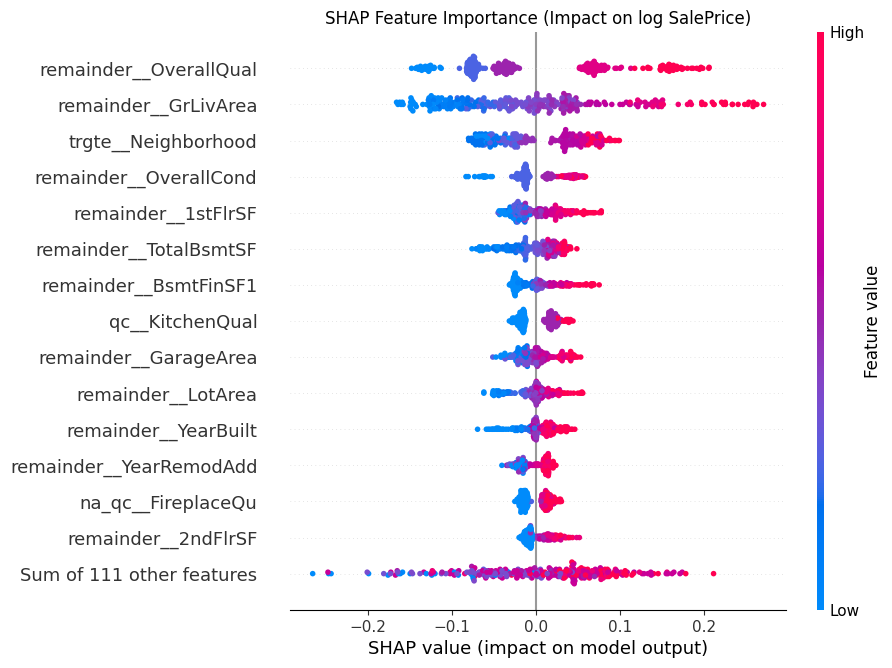

In [16]:
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))

from data import DataExtractor

data_loader = DataExtractor()
X_train, X_test = data_loader.train_data()[0], data_loader.test_data()[0]

pipeline = joblib.load(PROJECT_ROOT / "models" / "xgb_best_pipeline.joblib")

X_test_transformed=pipeline[:-1].transform(X_test)
feature_names=pipeline.named_steps["preprocessing"].get_feature_names_out()
X_test_df=pd.DataFrame(X_test_transformed, columns=feature_names, index=X_test.index)

explainer=shap.TreeExplainer(pipeline.named_steps["model"])
shap_values=explainer(X_test_df)

plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP Feature Importance (Impact on log SalePrice)")
plt.show()